# Evaluating embedding models with Nepali Q/A pairs

Compares embedding models by ranking each question against all answers in `qa_pairs.json`. The answer paired with each question is the correct match. Reports Recall@K and MRR.

Notebook flow: load Q/A pairs > choose models > rank answers > compare results.


In [40]:
!pip install -q -r requirements.txt


In [41]:
import hashlib, json, re, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import torch

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
CACHE = Path('emb_cache')
CACHE.mkdir(exist_ok=True)
QA_PATH = Path('qa_pairs.json')
print('device:', DEVICE)

def norm(text):
    text = unicodedata.normalize('NFC', str(text)).replace('\u200b', '')
    return re.sub(r'\s+', ' ', text).strip()


device: cuda


## 1. Load Q/A pairs

Each pair is one evaluation example. The paired answer is the correct result for its question.


In [42]:
qa_pairs = json.loads(QA_PATH.read_text(encoding='utf-8-sig'))
qa_pairs = [
    {'question': norm(row['question']), 'answer': norm(row['answer'])}
    for row in qa_pairs
    if row.get('question') and row.get('answer')
]
assert qa_pairs, f'No Q/A pairs found in {QA_PATH.resolve()}'

questions = [row['question'] for row in qa_pairs]
answers = [row['answer'] for row in qa_pairs]
print(f'{len(qa_pairs)} Q/A pairs loaded')


22 Q/A pairs loaded


## 2. Models to compare

Adjust `RUN` to choose which models to evaluate. Prefixes and prompt names are set for models that expect them.


In [43]:
E5_INSTR = 'Instruct: Given a Nepali question, retrieve the answer that best answers the question\nQuery: '

MODELS = {
    'bge-m3': dict(hf='BAAI/bge-m3', max_len=1024),
    'me5-large-instruct': dict(hf='intfloat/multilingual-e5-large-instruct', q_prefix=E5_INSTR, max_len=512),
    'me5-base': dict(hf='intfloat/multilingual-e5-base', q_prefix='query: ', a_prefix='passage: ', max_len=512),
    'qwen3-emb-0.6b': dict(hf='Qwen/Qwen3-Embedding-0.6B', q_prompt_name='query', max_len=1024, bs=8),
    'nepali-embedder-v1': dict(hf='premmm/nepali-embedder-v1', max_len=512),
    'minilm-nepali': dict(hf='jangedoo/all-MiniLM-L6-v3-nepali', max_len=256),
}
RUN = list(MODELS)


## 3. Embed questions and answers

Embeddings are cached in `emb_cache/`, so unchanged inputs do not need to be encoded again.


In [44]:
from sentence_transformers import SentenceTransformer

def embed_model(name, cfg, questions, answers):
    items = {'question': questions, 'answer': answers}
    files = {}
    for side, values in items.items():
        prefix = cfg.get('q_prefix' if side == 'question' else 'a_prefix', '')
        prompt = cfg.get('q_prompt_name') if side == 'question' else None
        payload = json.dumps([cfg['hf'], side, prefix, prompt, values], ensure_ascii=False)
        digest = hashlib.sha256(payload.encode('utf-8')).hexdigest()[:12]
        files[side] = (CACHE / f'{name}_{side}_{digest}.npy', prefix, prompt)

    embeddings = {}
    missing = [side for side, (file, _, _) in files.items() if not file.exists()]
    for side in items:
        file, _, _ = files[side]
        if file.exists():
            embeddings[side] = np.load(file)

    if missing:
        model = SentenceTransformer(
            cfg['hf'], device=DEVICE, trust_remote_code=cfg.get('trust', False)
        )
        model.max_seq_length = cfg.get('max_len', 512)
        for side in missing:
            file, prefix, prompt = files[side]
            values = [prefix + value for value in items[side]]
            kwargs = {'prompt_name': prompt} if prompt else {}
            vectors = model.encode(
                values,
                batch_size=cfg.get('bs', 16),
                normalize_embeddings=True,
                show_progress_bar=True,
                convert_to_numpy=True,
                **kwargs,
            )
            np.save(file, vectors)
            embeddings[side] = vectors
        del model
        if DEVICE == 'cuda':
            torch.cuda.empty_cache()

    return embeddings['question'], embeddings['answer']


## 4. Rank answers and score each model

For each question, answers are sorted by embedding similarity. Its paired answer is the single correct match.


In [45]:
results = []
pair_results = []

for name in RUN:
    cfg = MODELS[name]
    print(f'=== {name} ===')
    try:
        q_vectors, a_vectors = embed_model(name, cfg, questions, answers)
    except Exception as ex:
        print('  skipped:', repr(ex)[:200])
        continue

    scores = q_vectors @ a_vectors.T
    rankings = np.argsort(-scores, axis=1)
    ranks = np.array([
        int(np.flatnonzero(row == i)[0]) + 1
        for i, row in enumerate(rankings)
    ])
    results.append({
        'model': name,
        'MRR': float(np.mean(1 / ranks)),
        'Recall@1': float(np.mean(ranks <= 1)),
        'Recall@3': float(np.mean(ranks <= 3)),
        'Recall@5': float(np.mean(ranks <= 5)),
    })

    for i, rank in enumerate(ranks):
        best_answer = int(rankings[i, 0])
        pair_results.append({
            'model': name,
            'question': questions[i],
            'correct_answer': answers[i],
            'correct_answer_rank': int(rank),
            'top_answer': answers[best_answer],
        })

if not results:
    raise RuntimeError('No models completed successfully. Check the model errors above.')

results_df = pd.DataFrame(results).sort_values('MRR', ascending=False).reset_index(drop=True)
pair_results_df = pd.DataFrame(pair_results)
results_df.to_csv('embedding_eval_results.csv', index=False)
results_df.round(3)


=== bge-m3 ===


Batches: 100%|██████████| 2/2 [00:10<00:00,  5.27s/it]


=== me5-large-instruct ===


Batches: 100%|██████████| 2/2 [00:00<00:00, 14.48it/s]


=== me5-base ===


Batches: 100%|██████████| 2/2 [00:00<00:00, 16.12it/s]


... (3 outputs left out)

Batches: 100%|██████████| 2/2 [00:00<00:00, 13.36it/s]


=== minilm-nepali ===


Batches: 100%|██████████| 2/2 [00:00<00:00, 30.82it/s]


,model,MRR,Recall@1,Recall@3,Recall@5
0,bge-m3,0.797,0.727,0.818,0.909
1,me5-large-instruct,0.757,0.727,0.727,0.818
2,qwen3-emb-0.6b,0.720,0.682,0.682,0.773
3,nepali-embedder-v1,0.690,0.591,0.773,0.773
4,me5-base,0.683,0.591,0.682,0.818
5,minilm-nepali,0.680,0.591,0.727,0.727


## 5. Compare models


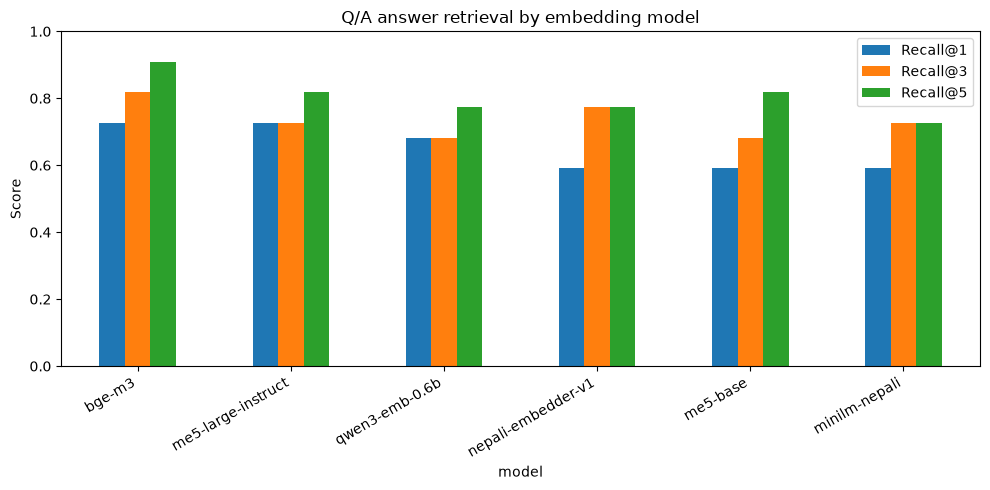

In [46]:
import matplotlib.pyplot as plt

results_df.set_index('model')[['Recall@1', 'Recall@3', 'Recall@5']].plot.bar(
    figsize=(10, 5), ylim=(0, 1)
)
plt.ylabel('Score')
plt.title('Q/A answer retrieval by embedding model')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


## 6. Inspect misses

Shows questions where the best model did not rank its paired answer first.


In [47]:
if not results_df.empty:
    best_model = results_df.iloc[0]['model']
    misses = pair_results_df[
        (pair_results_df['model'] == best_model)
        & (pair_results_df['correct_answer_rank'] > 1)
    ].sort_values('correct_answer_rank')
    print('Best model:', best_model)
    display(misses[['question', 'correct_answer_rank', 'correct_answer', 'top_answer']].head(10))


Best model: bge-m3


,question,correct_answer_rank,correct_answer,top_answer
12,काम गर्दागर्दै वा सोही क्रममा भएको दुर्घटनाको ...,2,रोजगार अवधि।,जानजानी वा लापरवाहीपूर्वक कार्य गरेमा
5,श्रम अदालतको निर्णय कुन आधारमा मान्य हुनेछ?,3,बहुमत सदस्यको निर्णय,श्रम अदालतले त्यस्तो व्यक्तिलाई दुई वर्षसम्म क...
20,"प्रतिष्ठानले श्रमिकको सेवा, हित र सुविधा सम्बन...",4,यस ऐनमा उल्लेखित न्यूनतम मापदण्ड र सामूहिक सम्...,यो ऐन वा यस ऐन अन्तर्गत बनेको नियम तथा निर्देश...
9,'आकस्मिक रोजगारी' भन्नाले के बुझिन्छ?,4,रोजगारदाताले श्रमिकलाई एक महिनाको अवधिमा सात द...,रोजगार अवधि।
3,ट्रेड युनियन महासङ्घहरूमध्येबाट मन्त्रालयले मन...,8,कम्तीमा दुई जना महिला सहित पाँच जना।,बहुमत सदस्यको निर्णय
7,श्रम आपूर्तिकर्ताले श्रमिकलाई पारिश्रमिक र अन्...,15,ऐन बमोजिम निर्धारित भएको भन्दा कम नहुने गरी।,रोजगारदाताले प्रत्येक श्रमिकको जुनसुकै प्रकारक...
